# MEMC cvičení 9 – Pojišťovna kompletně

---

Ve **cvičení 2** jsme pojišťovnu postavili a došli k prvnímu odhadu pravděpodobnosti úpadku. Tam jsme ale narazili: hrubý pás $\pm 2$ směrodatné chyby u vzácných jevů nestačí, a na otázku „kolik kapitálu potřebujeme" jsme vůbec nedošli.

Teď máme nástroje ze cvičení 3 až 7 a úlohu dořešíme.

| Co použijeme | Odkud |
|---|---|
| $R = \sqrt{\gamma}$, geometrické mezery | inverzní transformace, cvičení 3 a 4 |
| okamžiky požadavků během roku | uspořádané výběry, cvičení 5 |
| intervaly spolehlivosti (CLV, Čebyšev, Wilson) | cvičení 0 a 2 |
| vzácné úpadky bez miliard běhů | vážení podle důležitosti, cvičení 7 |

Na konci budeme umět odpovědět na otázku, kterou pojišťovnu opravdu zajímá: **jaký kapitál stačí, aby pravděpodobnost úpadku byla pod jedno promile?**

In [1]:
import math
import random
import time
from bisect import bisect_right

import matplotlib.pyplot as plt

random.seed(1)  # opakovatelné výsledky


def estimate(sampler, n):
    """Běžné Monte Carlo: průměr n volání generátoru a jeho směrodatná chyba sigma/sqrt(n)."""
    s = s2 = 0.0
    for _ in range(n):
        x = sampler()
        s += x
        s2 += x * x
    mean = s / n
    var = max(s2 / n - mean * mean, 0.0)
    return mean, math.sqrt(var / n)


def check(name, mean, se, exact, k=5):
    """Vypíše odhad a ověří, že leží do k směrodatných chyb od přesné hodnoty."""
    print(f"{name}: {mezery(mean, ',.5g')} +- {mezery(se, ',.2g')}  (přesně {mezery(exact, ',.5g')})")
    assert abs(mean - exact) <= k * se, name


def Phi(x):
    """Distribuční funkce N(0, 1)."""
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))


def mezery(x, spec=","):
    """Číslo s mezerami místo čárek jako oddělovač tisíců."""
    return format(x, spec).replace(",", " ")

## 1. Model a generátory

Připomenutí modelu ze cvičení 2: rok má $N$ intervalů, v každém nezávisle nastane požadavek s pravděpodobností $p$, jeho výše je $X = L\cdot R$ s hustotou $R$ rovnou $2r$ na $[0,1]$. Kapitál je $K$, k úpadku dojde právě když roční výplaty $T$ převýší $K$.

Dva generátory, které teď umíme odvodit:

**Výše požadavku** (inverzní transformace, cvičení 4). Z $F(r) = r^2$ plyne $F^{-1}(\gamma) = \sqrt{\gamma}$, tedy $R = \sqrt{\gamma}$.

**Mezera mezi požadavky** (geometrické rozdělení, cvičení 3). Počet prázdných intervalů před dalším požadavkem je geometrický a umíme ho vyrobit jedním číslem:

$$G = \left\lfloor \frac{\ln \gamma}{\ln(1-p)} \right\rfloor .$$

Místo $N$ losování tak uděláme jen tolik, kolik je požadavků.

In [2]:
SCENAR_A = dict(N=365, p=0.05, L=10_000, K=200_000)
SCENAR_B = dict(N=1000, p=0.15, L=100_000, K=10_000_000)


def pozadavek(L):
    """Výše jednoho požadavku: L * R, R má hustotu 2r na [0, 1] (cvičení 4: R = sqrt(γ))."""
    return L * math.sqrt(random.random())


def rocni_vyplaty_pomale(N, p, L):
    """Doslovná simulace: projdeme všech N intervalů."""
    T = 0.0
    for _ in range(N):
        if random.random() < p:
            T += pozadavek(L)
    return T


def rocni_vyplaty(N, p, L):
    """Roční výplaty T: skáčeme geometrickými mezerami (cvičení 3)."""
    lq = math.log(1.0 - p)
    T = 0.0
    pos = -1
    while True:
        pos += 1 + int(math.log(1.0 - random.random()) / lq)   # 1 - γ je také rovnoměrné a nikdy 0
        if pos >= N:
            return T
        T += pozadavek(L)


def teorie(N, p, L, K):
    """Přesné E T, D T a aproximace p_u z CLV."""
    mu = 2 * L / 3
    EX2 = L * L / 2
    ET = N * p * mu
    VarT = N * (p * EX2 - (p * mu) ** 2)
    return ET, VarT, 1 - Phi((K - ET) / math.sqrt(VarT))


sc = SCENAR_A
ET, VarT, p_clv = teorie(**sc)

n = 100_000
t0 = time.perf_counter()
m, se = estimate(lambda: rocni_vyplaty_pomale(sc["N"], sc["p"], sc["L"]), 20_000)
t_pomale = (time.perf_counter() - t0) / 20_000
check("E T (doslovná)", m, se, ET)

t0 = time.perf_counter()
m, se = estimate(lambda: rocni_vyplaty(sc["N"], sc["p"], sc["L"]), n)
t_rychle = (time.perf_counter() - t0) / n
check("E T (geometrické mezery)", m, se, ET)
print(f"zrychlení: {t_pomale / t_rychle:.0f}x  ({t_pomale * 1e6:.0f} → {t_rychle * 1e6:.1f} mikrosekund na rok)")

E T (doslovná): 1.2177e+05 +- 2.1e+02  (přesně 1.2167e+05)
E T (geometrické mezery): 1.2161e+05 +- 93  (přesně 1.2167e+05)
zrychlení: 4x  (14 → 3.6 mikrosekund na rok)


## 2. Průběh roku: okamžiky požadavků

Pro samotné $p_u$ nám stačí celková výplata $T$. Když ale chceme vidět **průběh** roku, potřebujeme okamžiky požadavků — a ty dostaneme ze cvičení 5: $k$ seřazených rovnoměrných čísel vyrobíme v čase $O(k)$ bez třídění, rekurencí shora dolů

$$\gamma_{(k)} = \gamma_{(k+1)}\cdot V^{1/k}, \qquad \gamma_{(n)} = V^{1/n}.$$

Počet požadavků v roce je $\operatorname{Binomické}(N, p)$, jejich okamžiky jsou pak rovnoměrné a nezávislé — tedy přesně seřazený rovnoměrný výběr přeškálovaný na délku roku.

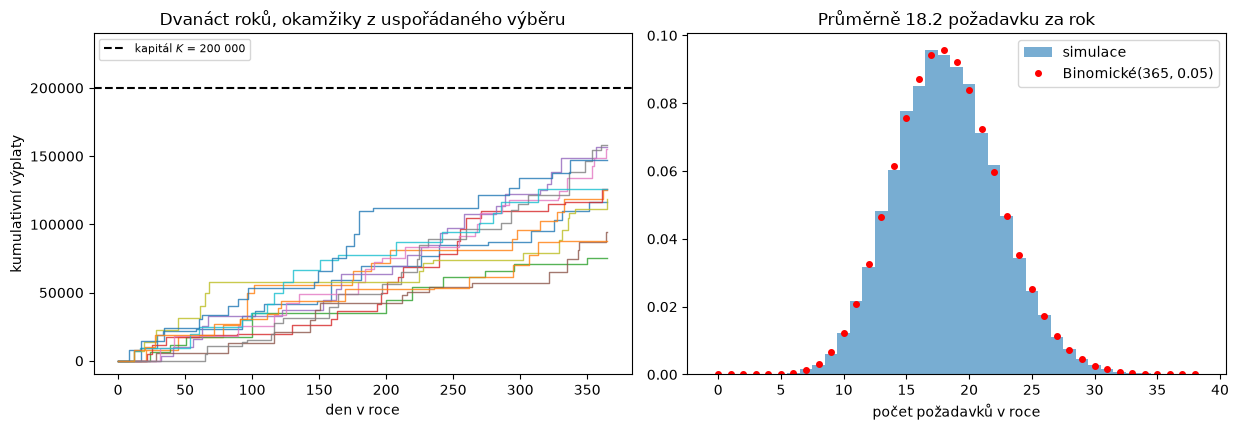

In [3]:
def usporadane_rovnomerne(n):
    """n seřazených rovnoměrných čísel na (0, 1) v čase O(n) (cvičení 5)."""
    out = [0.0] * n
    u = 1.0
    for k in range(n, 0, -1):
        u *= random.random() ** (1.0 / k)
        out[k - 1] = u
    return out


def binomicke(N, p):
    """Počet úspěchů z N pokusů, přes geometrické mezery (cvičení 3)."""
    lq = math.log(1.0 - p)
    pos, k = -1, 0
    while True:
        pos += 1 + int(math.log(1.0 - random.random()) / lq)
        if pos >= N:
            return k
        k += 1


def rok_prubeh(N, p, L):
    """Jeden rok jako (okamžiky, kumulativní výplaty)."""
    k = binomicke(N, p)
    casy = [t * N for t in usporadane_rovnomerne(k)]
    kum, s = [], 0.0
    for _ in casy:
        s += pozadavek(L)
        kum.append(s)
    return casy, kum


sc = SCENAR_A
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

ax = axes[0]
for _ in range(12):
    casy, kum = rok_prubeh(sc["N"], sc["p"], sc["L"])
    ax.step([0] + casy + [sc["N"]], [0.0] + kum + [kum[-1] if kum else 0.0],
            where="post", lw=1, alpha=0.8)
ax.axhline(sc["K"], color="k", ls="--", label=f"kapitál $K$ = {mezery(sc['K'])}")
ax.set_xlabel("den v roce")
ax.set_ylabel("kumulativní výplaty")
ax.set_ylim(top=sc["K"] * 1.2)
ax.set_title("Dvanáct roků, okamžiky z uspořádaného výběru")
ax.legend(loc="upper left", fontsize=8)

ax = axes[1]
pocty = [binomicke(sc["N"], sc["p"]) for _ in range(50_000)]
kmax = max(pocty) + 1
ax.hist(pocty, bins=[k - 0.5 for k in range(kmax + 1)], density=True, alpha=0.6, label="simulace")
lam = sc["N"] * sc["p"]
ax.plot(range(kmax), [math.comb(sc["N"], k) * sc["p"] ** k * (1 - sc["p"]) ** (sc["N"] - k) for k in range(kmax)],
        "ro", ms=4, label=f"Binomické({sc['N']}, {sc['p']})")
ax.set_xlabel("počet požadavků v roce")
ax.set_title(f"Průměrně {lam:.1f} požadavku za rok")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Interval spolehlivosti pro $p_u$

Odhad $\hat p = \bar\xi_M$ z $M$ běhů je průměr Bernoulliho veličin. Interval kolem něj umíme spočítat čtyřmi způsoby (spolehlivost $1-\alpha = 95\,\%$, $\hat\sigma = \sqrt{\hat p(1-\hat p)}$):

| Metoda | Interval | Poznámka |
|--------|----------|----------|
| CLV | $\hat p \pm 1.96\,\hat\sigma/\sqrt{M}$ | nejpoužívanější, dobrý pro větší $M\hat p$ |
| Čebyšev | $\hat p \pm \hat\sigma/\sqrt{M\alpha}$ | platí vždy (s přesným $\sigma$), 2.3× širší |
| Čebyšev, $\sigma = 1/2$ | $\hat p \pm 1/(2\sqrt{M\alpha})$ | opravdu garantovaný, ale hrubý |
| Wilson | upravený střed a šířka | funguje i pro $\hat p$ blízko nuly |

Wilsonův interval je

$$\frac{\hat p + \frac{z^2}{2M}}{1 + \frac{z^2}{M}} \;\pm\; \frac{z}{1 + \frac{z^2}{M}}\sqrt{\frac{\hat p(1-\hat p)}{M} + \frac{z^2}{4M^2}}, \qquad z = 1.96.$$

Proč zrovna Wilson: intervaly z CLV i z Čebyševa stojí na $\hat\sigma$, a když $\hat p = 0$, je $\hat\sigma = 0$ a interval se smrskne na bod $[0,0]$ — tedy na tvrzení „úpadek je nemožný". Wilson má šířku odvozenou jinak a tahle past se mu vyhne.

In [4]:
def upadek(sc, M):
    """Podíl z M simulovaných roků, ve kterých výplaty přesáhly K."""
    N, p, L, K = sc["N"], sc["p"], sc["L"], sc["K"]
    return sum(rocni_vyplaty(N, p, L) > K for _ in range(M)) / M


def _meze(stred, pol):
    return max(0.0, stred - pol), min(1.0, stred + pol)


def interval_clv(ph, M, z=1.96):
    return _meze(ph, z * math.sqrt(ph * (1 - ph) / M))


def interval_cheb(ph, M, alpha=0.05):
    return _meze(ph, math.sqrt(ph * (1 - ph) / (M * alpha)))


def interval_cheb_nejhorsi(ph, M, alpha=0.05):
    return _meze(ph, 0.5 / math.sqrt(M * alpha))


def interval_wilson(ph, M, z=1.96):
    d = 1 + z * z / M
    stred = (ph + z * z / (2 * M)) / d
    pol = z / d * math.sqrt(ph * (1 - ph) / M + z * z / (4 * M * M))
    return _meze(stred, pol)


M_ = 20_000
ph = upadek(SCENAR_B, M_)
print(f"scénář B (úpadek v polovině roků), M = {mezery(M_)}: p_u = {ph:.4f}   (CLV: {teorie(**SCENAR_B)[2]:.4f})")
for nazev, f in (("CLV", interval_clv), ("Čebyšev", interval_cheb), ("Wilson", interval_wilson)):
    lo, hi = f(ph, M_)
    print(f"  {nazev:8s} [{lo:.4f}, {hi:.4f}]   šířka {hi - lo:.4f}")

print("\nscénář A (vzácný úpadek), rostoucí M:")
print(f"{'M':>8s} {'p odhad':>9s}   {'interval CLV':>22s}   {'interval Wilson':>22s}")
for M_ in (10, 30, 100, 1_000, 10_000, 100_000):
    ph = upadek(SCENAR_A, M_)
    lo1, hi1 = interval_clv(ph, M_)
    lo2, hi2 = interval_wilson(ph, M_)
    print(f"{mezery(M_, '8,d')} {ph:9.5f}   [{lo1:.5f}, {hi1:.5f}]   [{lo2:.5f}, {hi2:.5f}]")

scénář B (úpadek v polovině roků), M = 20 000: p_u = 0.5004   (CLV: 0.5000)
  CLV      [0.4935, 0.5074]   šířka 0.0139
  Čebyšev  [0.4846, 0.5163]   šířka 0.0316
  Wilson   [0.4935, 0.5074]   šířka 0.0139

scénář A (vzácný úpadek), rostoucí M:
       M   p odhad             interval CLV          interval Wilson
      10   0.00000   [0.00000, 0.00000]   [0.00000, 0.27754]
      30   0.00000   [0.00000, 0.00000]   [0.00000, 0.11352]
     100   0.00000   [0.00000, 0.00000]   [0.00000, 0.03699]
   1 000   0.00700   [0.00183, 0.01217]   [0.00339, 0.01438]
  10 000   0.00510   [0.00370, 0.00650]   [0.00388, 0.00670]
 100 000   0.00729   [0.00676, 0.00782]   [0.00678, 0.00784]


U scénáře B, kde $p_u \approx 0.5$, se CLV a Wilson prakticky shodují a Čebyšev je zhruba 2.3× širší (podíl $4.47/1.96$).

U scénáře A je vidět past: pro malé $M$ nepadne ani jeden úpadek, $\hat p = 0$ a interval z CLV je bod $[0,0]$. Wilson je správně široký a nenulový.

### Pokrytí: drží intervaly, co slibují?

Slovo „95% interval" znamená, že při mnoha opakováních pokryje pravdu v 95 % případů. Ověříme to: jako pravdu vezmeme odhad z velkého počtu běhů a pak mnohokrát zopakujeme odhad z malého $M$.

In [5]:
M_ref = 500_000
p_pravda = upadek(SCENAR_A, M_ref)
print(f"referenční hodnota p_u = {p_pravda:.5f}  (z {mezery(M_ref)} běhů)\n")

metody = (
    ("CLV", interval_clv),
    ("Čebyšev (odhad sigma)", interval_cheb),
    ("Čebyšev (sigma = 1/2)", interval_cheb_nejhorsi),
    ("Wilson", interval_wilson),
)


def tabulka_pokryti(M_, behy):
    ok = {nazev: 0 for nazev, _ in metody}
    sirky = {nazev: 0.0 for nazev, _ in metody}
    nulove = 0
    for _ in range(behy):
        ph = upadek(SCENAR_A, M_)
        nulove += ph == 0
        for nazev, f in metody:
            lo, hi = f(ph, M_)
            ok[nazev] += lo <= p_pravda <= hi
            sirky[nazev] += hi - lo
    print(f"M = {M_}, {behy} opakování; běhů bez jediného úpadku: {nulove / behy:.1%}")
    print(f"  {'metoda':24s} {'pokrytí':>8s} {'průměrná šířka':>16s}")
    for nazev, _ in metody:
        print(f"  {nazev:24s} {ok[nazev] / behy:8.1%} {sirky[nazev] / behy:16.4f}")
    print()


tabulka_pokryti(100, 1000)
tabulka_pokryti(1000, 400)

referenční hodnota p_u = 0.00717  (z 500 000 běhů)

M = 100, 1000 opakování; běhů bez jediného úpadku: 51.2%
  metoda                    pokrytí   průměrná šířka
  CLV                         48.7%           0.0178
  Čebyšev (odhad sigma)       48.8%           0.0318
  Čebyšev (sigma = 1/2)      100.0%           0.2304
  Wilson                      96.6%           0.0468

M = 1000, 400 opakování; běhů bez jediného úpadku: 0.0%
  metoda                    pokrytí   průměrná šířka
  CLV                         94.8%           0.0102
  Čebyšev (odhad sigma)      100.0%           0.0187
  Čebyšev (sigma = 1/2)      100.0%           0.0777
  Wilson                      98.0%           0.0109



Závěry (čísla se mírně mění se semínkem, závěry ne):

- **$M = 100$:** zhruba v polovině opakování nepadne ani jeden úpadek, takže interval z CLV i Čebyšev s odhadnutým $\sigma$ jsou body $[0,0]$. Pokrytí je kolem **50 %**, ne slíbených 95 %. Wilson drží přes 95 %, i když je širší.
- **$M = 1000$:** nulové běhy už skoro nejsou, CLV pokrývá zhruba 93 % a Wilson 95–98 %.
- **Čebyšev s $\sigma = 1/2$** pokryje vždy, ale jeho šířka (kolem $0.23$ při $M = 100$) je mnohonásobek samotné hodnoty $p_u \approx 0.007$. Garance, ze které nic nezjistíte.

**Pravidlo:** u vzácných jevů potřebujete tolik běhů, aby očekávaný počet úpadků $M p_u$ byl aspoň ve stovkách. Pro $p_u \approx 0.007$ to znamená $M \sim 10^5$. A kdyby bylo $p_u \sim 10^{-6}$, potřebovali bychom $10^8$ běhů — to už je neúnosné.

Právě tady se vyplatí změnit metodu.

## 4. Vzácné úpadky: vážení podle důležitosti

Problém obyčejného Monte Carla u vzácného jevu je prostý: skoro všechny běhy přispějí nulou. Ze cvičení 7 víme, co s tím — **generovat z jiného rozdělení a vážit**.

Tady se nabízí hezká volba. Úpadek nastává, když je v roce neobvykle **hodně** požadavků. Tak losujme rok s větší pravděpodobností požadavku $q > p$ a chybu opravme vahou. Počet požadavků $k$ má pod $p$ pravděpodobnost $\binom{N}{k}p^k(1-p)^{N-k}$ a pod $q$ obdobně, takže

$$w(k) \;=\; \frac{P_p(k)}{P_q(k)} \;=\; \left(\frac{p}{q}\right)^{k}\left(\frac{1-p}{1-q}\right)^{N-k}.$$

Výše požadavků neměníme, ty se ve zlomku vykrátí. Odhad je

$$\hat p_u = \frac{1}{M}\sum_{i=1}^{M} w(k_i)\,\mathbf 1[T_i > K], \qquad k_i,\,T_i \text{ losované s } q .$$

Je **nestranný** pro libovolné $q \in (0,1)$ — $q$ ovlivní jen rozptyl.

Jak $q$ zvolit? Tak, aby se jev stal typickým: chceme $E_q\,T = K$, a protože $E_q T = N q \cdot \tfrac{2L}{3}$, vyjde

$$q^\star = \frac{K}{N\cdot 2L/3}.$$

Váhy počítáme **logaritmicky**, jinak podtečou.

In [6]:
def rok_s_poctem(N, prob, L):
    """Jeden rok losovaný s pravděpodobností prob; vrací (výplaty T, počet požadavků k)."""
    lq = math.log(1.0 - prob)
    T, pos, k = 0.0, -1, 0
    while True:
        pos += 1 + int(math.log(1.0 - random.random()) / lq)
        if pos >= N:
            return T, k
        T += pozadavek(L)
        k += 1


def p_upadku_vazenim(sc, M_, q=None):
    """P(T > K) vážením podle důležitosti: losujeme s q > p, vážíme poměrem věrohodností."""
    N, p, L, K = sc["N"], sc["p"], sc["L"], sc["K"]
    if q is None:
        q = min(K / (N * 2 * L / 3), 0.9)
    log_w1 = math.log(p / q)              # za každý požadavek
    log_w0 = math.log((1 - p) / (1 - q))  # za každý prázdný interval
    hodnoty = []
    for _ in range(M_):
        T, k = rok_s_poctem(N, q, L)
        hodnoty.append(math.exp(k * log_w1 + (N - k) * log_w0) if T > K else 0.0)
    m = sum(hodnoty) / M_
    var = sum((x - m) ** 2 for x in hodnoty) / (M_ - 1)
    return m, math.sqrt(var / M_), q


def p_upadku_obycejne(sc, M_):
    N, p, L, K = sc["N"], sc["p"], sc["L"], sc["K"]
    zasahy = sum(rocni_vyplaty(N, p, L) > K for _ in range(M_))
    ph = zasahy / M_
    return ph, math.sqrt(ph * (1 - ph) / M_), zasahy


M_ = 100_000
print(f"scénář A, M = {mezery(M_)} běhů pro obě metody\n")
print(f"{'K':>9} {'q*':>6}   {'obyčejné MC':>26}   {'vážení':>26}   {'zisk':>9}")
for K in (200_000, 250_000, 300_000):
    sc = dict(SCENAR_A, K=K)
    a, sa, zasahy = p_upadku_obycejne(sc, M_)
    b, sb, q = p_upadku_vazenim(sc, M_)
    zisk = f"{(sa / sb) ** 2:,.0f}x".replace(",", " ") if sa > 0 else "—"
    print(f"{mezery(K, '9,d')} {q:6.3f}   {a:11.3e} +- {sa:8.1e}   {b:11.3e} +- {sb:8.1e}   {zisk:>9}")
    if zasahy == 0:
        print(f"{'':>9} {'':>6}   (obyčejné MC: 0 zásahů ze {mezery(M_)} → odhad 0, chyba 0, žádná informace)")

scénář A, M = 100 000 běhů pro obě metody

        K     q*                  obyčejné MC                       vážení        zisk
  200 000  0.082     7.080e-03 +-  2.7e-04     7.077e-03 +-  6.1e-05         19x
  250 000  0.103     6.000e-05 +-  2.4e-05     6.521e-05 +-  1.2e-06        433x
  300 000  0.123     0.000e+00 +-  0.0e+00     1.765e-07 +-  7.6e-09           —
                   (obyčejné MC: 0 zásahů ze 100 000 → odhad 0, chyba 0, žádná informace)


Co tabulka říká:

- Při $K = 200\,000$ (původní scénář) je zisk kolem **dvaceti**: vážení potřebuje asi 20× méně běhů na stejnou přesnost.
- Při $K = 250\,000$ roste zisk do **stovek**.
- Při $K = 300\,000$ obyčejné Monte Carlo ze sta tisíc běhů **netrefí ani jednou**. Vrátí odhad $0$ se směrodatnou chybou $0$ — tedy sebejisté a nesmyslné tvrzení, že úpadek je nemožný. Vážení pořád vrací konečný odhad s použitelnou chybou.

To je celá pointa vzácných jevů: nejde jen o to, že obyčejné MC je pomalé. Ono **tiše selže** a vypadá přitom spolehlivě. Kontrola je snadná — u obyčejného MC se vždycky ptejte na počet zásahů, ne jen na odhad.

## 5. Kolik kapitálu potřebujeme?

Dosud jsme $K$ brali jako dané. Pojišťovnu ale zajímá opačná otázka: **jaké $K$ zajistí úpadek s pravděpodobností nejvýše $1\,\%$?**

Odpověď dává **kvantil** rozdělení $T$, a stačí k tomu jediná simulace: nasimulujeme mnoho ročních výplat, seřadíme je, a pak pro libovolné $K$ odečteme podíl těch, které ho převýšily. Jedna sada vzorků odpoví na otázku pro všechna $K$ najednou.

potřebný kapitál podle cílové pravděpodobnosti úpadku:
  úpadek nejvýše  5.0%: K = 172 174
  úpadek nejvýše  1.0%: K = 195 027
  úpadek nejvýše  0.1%: K = 222 693


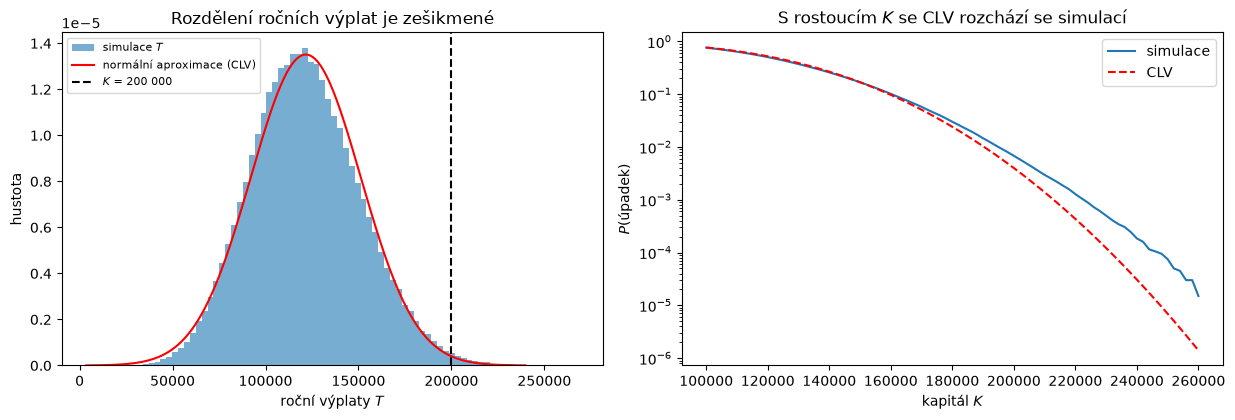

In [7]:
sc = SCENAR_A
M_ = 200_000
T_vzorky = sorted(rocni_vyplaty(sc["N"], sc["p"], sc["L"]) for _ in range(M_))


def p_upadku_z_kvantilu(K):
    """P(T > K) z uspořádaného pole simulovaných výplat."""
    return (M_ - bisect_right(T_vzorky, K)) / M_


print("potřebný kapitál podle cílové pravděpodobnosti úpadku:")
for cil in (0.05, 0.01, 0.001):
    K_cil = T_vzorky[int((1 - cil) * M_)]
    print(f"  úpadek nejvýše {cil:5.1%}: K = {mezery(K_cil, ',.0f')}")

ET, VarT, _ = teorie(**sc)
sigma = math.sqrt(VarT)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
ax.hist(T_vzorky, bins=80, density=True, alpha=0.6, label="simulace $T$")
grid = [ET + sigma * (i / 50 - 4) for i in range(401)]
ax.plot(grid, [math.exp(-((x - ET) / sigma) ** 2 / 2) / (sigma * math.sqrt(2 * math.pi)) for x in grid],
        "r", label="normální aproximace (CLV)")
ax.axvline(sc["K"], color="black", linestyle="--", label=f"$K$ = {mezery(sc['K'])}")
ax.set_xlabel("roční výplaty $T$")
ax.set_ylabel("hustota")
ax.set_title("Rozdělení ročních výplat je zešikmené")
ax.legend(fontsize=8)

ax = axes[1]
Ks = [100_000 + 2_000 * i for i in range(81)]
ax.semilogy(Ks, [p if (p := p_upadku_z_kvantilu(K)) > 0 else None for K in Ks], label="simulace")
ax.semilogy(Ks, [1 - Phi((K - ET) / sigma) for K in Ks], "r--", label="CLV")
ax.set_xlabel("kapitál $K$")
ax.set_ylabel("$P(\\mathrm{úpadek})$")
ax.set_title("S rostoucím $K$ se CLV rozchází se simulací")
ax.legend()
plt.tight_layout()
plt.show()

Pravý graf je v logaritmické ose a ukazuje jádro problému: čím dál do chvostu, tím víc se normální aproximace rozchází se simulací — a vždycky na tu nebezpečnou stranu, tedy riziko **podhodnocuje**. Přitom právě chvost (vzácné velké škody) pojišťovnu zajímá nejvíc.

Všimněte si také, kde křivka ze simulace končí: pod zhruba $10^{-5}$ už nemá z čeho čerpat, protože $200\,000$ vzorků prostě neobsahuje vzácnější jevy. Pokud bychom chtěli kapitál pro $p_u = 10^{-6}$, musíme sáhnout po vážení z oddílu 4.

## 6. Alternativa: NumPy

Celý model jde napsat bez cyklů. Počet požadavků v roce je $\operatorname{Binomické}(N, p)$, výše všech požadavků vygenerujeme najednou a `bincount` je posčítá po rocích.

In [8]:
try:
    import numpy as np

    rng = np.random.default_rng(1)

    def rocni_vyplaty_numpy(sc, M_, p=None):
        """M ročních výplat najednou; p lze přepsat (pro vážení podle důležitosti)."""
        p = sc["p"] if p is None else p
        pocty = rng.binomial(sc["N"], p, size=M_)
        vysky = sc["L"] * np.sqrt(rng.random(pocty.sum()))
        T = np.bincount(np.repeat(np.arange(M_), pocty), weights=vysky, minlength=M_)
        return T, pocty

    sc = SCENAR_A
    M_ = 2_000_000

    t0 = time.perf_counter()
    T, _ = rocni_vyplaty_numpy(sc, M_)
    ph = float(np.mean(T > sc["K"]))
    t_np = time.perf_counter() - t0
    lo, hi = interval_wilson(ph, M_)
    print(f"obyčejné, M = {mezery(M_)}: p_u = {ph:.5f}, 95% Wilson [{lo:.5f}, {hi:.5f}]   ({t_np:.2f} s)")

    # vážení podle důležitosti vektorově
    K_cil = 300_000
    q = K_cil / (sc["N"] * 2 * sc["L"] / 3)
    t0 = time.perf_counter()
    T, pocty = rocni_vyplaty_numpy(sc, M_, p=q)
    log_w = pocty * np.log(sc["p"] / q) + (sc["N"] - pocty) * np.log((1 - sc["p"]) / (1 - q))
    w = np.where(T > K_cil, np.exp(log_w), 0.0)
    t_np = time.perf_counter() - t0
    print(f"vážení,   K = {mezery(K_cil)}: p_u = {w.mean():.3e} +- {w.std(ddof=1) / math.sqrt(M_):.1e}   ({t_np:.2f} s)")
    zisk = w.mean() * (1 - w.mean()) / w.std(ddof=1) ** 2   # rozptyl obyčejného MC / rozptyl vážení
    print(f"           obyčejné MC by na stejnou přesnost potřebovalo řádově {zisk:,.0f}x víc běhů".replace(",", " "))
except ModuleNotFoundError:
    print("NumPy není nainstalované, spusťte:  uv sync")

obyčejné, M = 2 000 000: p_u = 0.00706, 95% Wilson [0.00695, 0.00718]   (0.81 s)
vážení,   K = 300 000: p_u = 1.703e-07 +- 1.5e-09   (2.33 s)
           obyčejné MC by na stejnou přesnost potřebovalo řádově 37 369x víc běhů


## Shrnutí

| Krok | Nástroj | Odkud |
|------|---------|-------|
| výše požadavku $R = \sqrt{\gamma}$ | inverzní transformace | cvičení 4 |
| mezery mezi požadavky | geometrické rozdělení jedním číslem | cvičení 3 |
| okamžiky požadavků v roce | uspořádaný výběr v $O(k)$ | cvičení 5 |
| interval spolehlivosti pro $p_u$ | CLV / Čebyšev / **Wilson** | cvičení 0 a 2 |
| vzácný úpadek | vážení podle důležitosti, $q^\star = K/(N\cdot 2L/3)$ | cvičení 7 |
| potřebný kapitál | kvantil z jedné sady vzorků | cvičení 5 |

Tři věci, které si odnést:

1. **Normální aproximace podhodnocuje chvost.** U zešikmeného $T$ dává CLV $p_u \approx 0.004$ tam, kde je pravda $0.007$ — a čím dál do chvostu, tím hůř.
2. **Interval z CLV selže právě tam, kde ho potřebujete.** Když $\hat p = 0$, tvrdí $[0,0]$. Wilson tuhle past nemá.
3. **U vzácných jevů obyčejné MC tiše selže.** Nula zásahů vypadá jako odpověď. Vážení podle důležitosti vrátí odhad i tam, kde obyčejné MC nemá jediný zásah.

---

**Model má ale jeden tichý předpoklad.** Celý kapitál $K$ (počáteční kapitál *plus celé roční pojistné*)
je k dispozici hned prvního ledna — proto stačilo sledovat roční součet a na pořadí požadavků nezáleželo.
Co se stane, když pojistné přitéká postupně a pojišťovnu může potopit smůla v načasování, je v sešitu
`aplikace/pojistovna_realisticky`.

### Zkuste si

1. Zkuste v `p_upadku_vazenim` různá $q$ (třeba $0.06$, $q^\star$, $0.2$) a sledujte směrodatnou chybu. Potvrdí se, že $q^\star$ je blízko optimu? Co se stane pro $q$ příliš velké?
2. Spočítejte kapitál pro $p_u = 10^{-6}$ vážením podle důležitosti. (Hledejte $K$ půlením intervalu, pro každé $K$ odhadněte $p_u$.)
3. Zkontrolujte nestrannost: pusťte vážení pro $K = 200\,000$ dvacetkrát a ověřte, že průměr odhadů sedí na referenční hodnotu do dvou směrodatných chyb.
4. Ve scénáři B je $p_u \approx 0.5$. Pomůže tam vážení? Spočítejte zisk a vysvětlete výsledek.
5. Model předpokládá nejvýše jeden požadavek za interval. Nahraďte počet požadavků v roce přímo Poissonovým rozdělením (cvičení 3) a porovnejte $p_u$. Jak velká je chyba z diskretizace?